# Lab Task 04 – Geometric Transformations with Custom Inputs

**Name:** Afzal Ali Ahmed
**Roll No:** 2024-SE-04
**Course:** Digital Image Processing Lab  |  **Instructor:** Engr. Fahad Nisar
**Semester:** Fifth  |  **Session:** 2024-28 (SE)

**Libraries (same as the practice notebook):** `numpy`, `cv2` (OpenCV), `matplotlib.pyplot`, `PIL.Image`, `PIL.ImageOps`. `os` (only to create the output folder). Nothing else is imported.

**Objective:** build one reusable `transform(image, operation, **params)` function that takes custom values, validates them, and performs scaling, cropping, flipping, translation and rotation.

> **How to run:** restart the kernel, then *Run All*. The very last cell asks for keyboard input (the interactive part); type `q` there to finish.

### 1. Importing libraries

In [1]:
import os
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import PIL.Image as Image
import PIL.ImageOps as ImageOps

### 2. Settings, limits and the error type

All limits are declared in one place and enforced inside `transform`:

| Limit | Value | Meaning |
|---|---|---|
| `MAX_SIDE` | 4000 px | largest allowed output width or height |
| `MAX_PIXELS` | 12,000,000 | largest allowed output area (width × height) |
| `MAX_SHIFT` | 100,000 px | largest allowed absolute translation offset |

Saved results are written into the **`output/`** folder (created automatically next to this notebook) with the prefix `result_`. The input image `image.jpg` stays outside it.

In [2]:
IMAGE_PATH = "image.jpg"   # input image, kept next to this notebook
OUTPUT_DIR = "output"      # every saved result goes here

MAX_SIDE = 4000
MAX_PIXELS = 12_000_000
MAX_SHIFT = 100_000

INTERPOLATIONS = {                       # Pillow resampling filters
    "nearest":  Image.Resampling.NEAREST,
    "bilinear": Image.Resampling.BILINEAR,
    "bicubic":  Image.Resampling.BICUBIC,
    "lanczos":  Image.Resampling.LANCZOS,
}
FLIP_DIRECTIONS = ("horizontal", "vertical", "both")

# required parameter names for every operation
OPERATIONS = {
    "scale":     ("fx", "fy", "interpolation"),
    "crop":      ("left", "top", "right", "bottom"),
    "flip":      ("direction",),
    "translate": ("tx", "ty"),
    "rotate":    ("angle", "expand"),
}


class TransformError(ValueError):
    """Raised for any invalid image, operation name or parameter."""

### 3. Loading and validating the image

* The file must exist, decode successfully and have non-zero width and height.
* **Colour handling:** OpenCV loads colour images as **BGR**, but matplotlib and Pillow expect **RGB**. The image is converted to RGB **once**, here, and every later step (and saving) works in RGB.
* **Libraries:** OpenCV loads the image and does the translation (`cv.warpAffine`, as in the practice notebook); Pillow does resize, crop, flip and rotate (`Image.resize`, `Image.crop`, `ImageOps.mirror/flip`, `Image.rotate`).
* The original is made read-only, and a backup copy is kept so we can prove at the end that it was never modified.

Width  : 452 px
Height : 678 px
Array shape (height, width, channels): (678, 452, 3)
Data type: uint8   Colour order: RGB


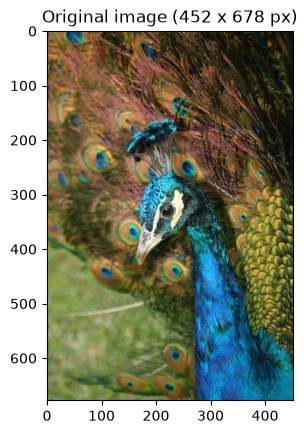

In [3]:
def load_image(path):
    try:
        with open(path, "rb"):
            pass
    except FileNotFoundError:
        raise TransformError(f"Image file not found: {path}  (keep it in the same folder as the notebook)")
    except OSError as error:
        raise TransformError(f"Image file cannot be opened: {path} ({error})")
    bgr = cv.imread(path, cv.IMREAD_COLOR)
    if bgr is None:
        raise TransformError(f"File exists but could not be decoded as an image: {path}")
    if bgr.ndim != 3 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise TransformError(f"Decoded image has invalid dimensions: {bgr.shape}")
    return cv.cvtColor(bgr, cv.COLOR_BGR2RGB)


original = load_image(IMAGE_PATH)
original.flags.writeable = False          # protect the original from accidental changes
original_backup = original.copy()         # used for the final "unchanged" check

orig_height, orig_width = original.shape[:2]   # shape is (rows, cols) = (height, width)
print(f"Width  : {orig_width} px")
print(f"Height : {orig_height} px")
print(f"Array shape (height, width, channels): {original.shape}")
print(f"Data type: {original.dtype}   Colour order: RGB")

plt.imshow(original)
plt.title(f"Original image ({orig_width} x {orig_height} px)")
plt.show()

### 4. Validation helpers

These are used **inside** `transform`, so the function is safe even when called directly with bad values.
`bool` is rejected on purpose for numeric parameters (otherwise `True` would silently act as `1`).

In [4]:
def check_image(image):
    if not isinstance(image, np.ndarray):
        raise TransformError(f"image must be a NumPy array, got {type(image).__name__}.")
    if image.dtype != np.uint8:
        raise TransformError(f"image must be 8-bit (uint8), got {image.dtype}.")
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] != 3):
        raise TransformError(f"Unsupported image shape {image.shape}; expected (H, W) or (H, W, 3).")
    if image.shape[0] == 0 or image.shape[1] == 0:
        raise TransformError("image has zero width or height.")


def real_number(name, value):
    """Return value as a finite float, or raise TransformError."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TransformError(f"'{name}' must be a number, got {value!r} ({type(value).__name__}).")
    try:
        number = float(value)
    except OverflowError:
        raise TransformError(f"'{name}' is too large to be used.")
    if not np.isfinite(number):
        raise TransformError(f"'{name}' must be finite (not NaN or infinity), got {number}.")
    return number


def whole_number(name, value):
    """Return value as an int; floats (even 10.0) and bools are rejected."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
        raise TransformError(f"'{name}' must be an integer, got {value!r} ({type(value).__name__}).")
    return int(value)


def interpolation_flag(value):
    if not isinstance(value, str):
        raise TransformError(f"'interpolation' must be text, got {value!r}.")
    key = value.strip().lower()
    if key not in INTERPOLATIONS:
        raise TransformError(f"Unsupported interpolation {value!r}. Choose from: {', '.join(INTERPOLATIONS)}.")
    return INTERPOLATIONS[key]


def check_output_size(width, height, what):
    if width < 1 or height < 1:
        raise TransformError(f"{what} would produce an empty image ({width} x {height} px).")
    if width > MAX_SIDE or height > MAX_SIDE:
        raise TransformError(f"{what} would produce {width} x {height} px; the maximum side is {MAX_SIDE} px.")
    if width * height > MAX_PIXELS:
        raise TransformError(f"{what} would produce {width * height:,} pixels; the maximum is {MAX_PIXELS:,}.")


def scaled_length(length, factor, name):
    exact = length * factor
    if not np.isfinite(exact) or exact > MAX_SIDE + 1:
        raise TransformError(f"Scale factor '{name}'={factor} makes the output larger than the maximum side of {MAX_SIDE} px.")
    return int(np.floor(exact + 0.5))     # round half up to an integer number of pixels

### 5. The reusable `transform` function

`transform(image, operation, **params)` is the single entry point. It validates the image, the operation name and the parameters, then calls the matching handler and returns a **new** array (the input is never modified).

| Operation | Parameters | Notes |
|---|---|---|
| `scale` | `fx`, `fy`, `interpolation` | factors > 0; output size is rounded to whole pixels |
| `crop` | `left`, `top`, `right`, `bottom` | integers; `right` and `bottom` are exclusive |
| `flip` | `direction` | `horizontal`, `vertical` or `both` |
| `translate` | `tx`, `ty` | pixels; **+tx = right, +ty = down**; canvas size unchanged; exposed area is black |
| `rotate` | `angle`, `expand` | degrees, about the image centre; **positive = counter-clockwise** on screen; exposed area is black |

In [5]:
def _scale(image, fx, fy, interpolation):
    height, width = image.shape[:2]
    fx = real_number("fx", fx)
    fy = real_number("fy", fy)
    if fx <= 0 or fy <= 0:
        raise TransformError(f"Scale factors must be greater than zero, got fx={fx}, fy={fy}.")
    flag = interpolation_flag(interpolation)
    new_width = scaled_length(width, fx, "fx")
    new_height = scaled_length(height, fy, "fy")
    check_output_size(new_width, new_height, "Scaling")
    resized = Image.fromarray(image).resize((new_width, new_height), resample=flag)   # size is (width, height)
    return np.array(resized)


def _crop(image, left, top, right, bottom):
    height, width = image.shape[:2]
    left = whole_number("left", left)
    top = whole_number("top", top)
    right = whole_number("right", right)
    bottom = whole_number("bottom", bottom)
    if not (0 <= left < right <= width):
        raise TransformError(f"Invalid horizontal range: need 0 <= left < right <= {width}, got left={left}, right={right}.")
    if not (0 <= top < bottom <= height):
        raise TransformError(f"Invalid vertical range: need 0 <= top < bottom <= {height}, got top={top}, bottom={bottom}.")
    cropped = Image.fromarray(image).crop((left, top, right, bottom))   # box is (x1, y1, x2, y2), x2/y2 exclusive
    return np.array(cropped)


def _flip(image, direction):
    if not isinstance(direction, str):
        raise TransformError(f"'direction' must be text, got {direction!r}.")
    key = direction.strip().lower()
    if key not in FLIP_DIRECTIONS:
        raise TransformError(f"Unsupported flip direction {direction!r}. Choose from: {', '.join(FLIP_DIRECTIONS)}.")
    picture = Image.fromarray(image)
    if key == "horizontal":
        flipped = ImageOps.mirror(picture)                 # left <-> right
    elif key == "vertical":
        flipped = ImageOps.flip(picture)                   # top <-> bottom
    else:
        flipped = ImageOps.flip(ImageOps.mirror(picture))  # both
    return np.array(flipped)


def _translate(image, tx, ty):
    height, width = image.shape[:2]
    tx = real_number("tx", tx)
    ty = real_number("ty", ty)
    if abs(tx) > MAX_SHIFT or abs(ty) > MAX_SHIFT:
        raise TransformError(f"Offsets must satisfy |tx|, |ty| <= {MAX_SHIFT}, got tx={tx}, ty={ty}.")
    matrix = np.float32([[1, 0, tx],
                         [0, 1, ty]])
    return cv.warpAffine(image, matrix, (width, height),      # dsize is (width, height)
                         flags=cv.INTER_LINEAR, borderMode=cv.BORDER_CONSTANT, borderValue=0)


def _rotate(image, angle, expand):
    height, width = image.shape[:2]
    angle = real_number("angle", angle)
    if not isinstance(expand, (bool, np.bool_)):
        raise TransformError(f"'expand' must be True or False, got {expand!r}.")
    angle = float(np.fmod(angle, 360.0))                # keeps accuracy for huge angles; 360 -> 0
    if expand:                                          # estimate the expanded canvas before rotating
        radians = np.radians(angle)
        cos_a, sin_a = abs(np.cos(radians)), abs(np.sin(radians))
        est_width = int(np.ceil(width * cos_a + height * sin_a - 1e-9))
        est_height = int(np.ceil(width * sin_a + height * cos_a - 1e-9))
        check_output_size(est_width, est_height, "Rotation with expand=True")
    rotated = Image.fromarray(image).rotate(angle, resample=Image.Resampling.BICUBIC,
                                            expand=bool(expand), fillcolor=0)   # positive = counter-clockwise
    check_output_size(rotated.width, rotated.height, "Rotation")
    return np.array(rotated)


HANDLERS = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}


def transform(image, operation, **params):
    """Apply one geometric operation and return the new image.

    operation : 'scale' | 'crop' | 'flip' | 'translate' | 'rotate'
    params    : the parameters listed in OPERATIONS for that operation (all required).
    """
    check_image(image)
    if not isinstance(operation, str):
        raise TransformError(f"operation must be text, got {operation!r}.")
    name = operation.strip().lower()
    if name not in OPERATIONS:
        raise TransformError(f"Unknown operation {operation!r}. Choose from: {', '.join(OPERATIONS)}.")
    required = OPERATIONS[name]
    missing = [p for p in required if params.get(p) is None]
    if missing:
        raise TransformError(f"Operation '{name}' is missing required parameter(s): {', '.join(missing)}.")
    unexpected = [p for p in params if p not in required]
    if unexpected:
        raise TransformError(f"Operation '{name}' does not accept parameter(s): {', '.join(unexpected)}.")
    result = HANDLERS[name](image, **params)
    if result.size == 0:
        raise TransformError("The operation produced an empty image.")
    return result

### 6. Helpers for user text, display and saving

User-typed text is checked **before** `transform` is called (`parse_*` functions); `transform` then checks everything again.

In [6]:
def parse_float(name, text):
    try:
        number = float(text.strip())
    except ValueError:
        raise TransformError(f"'{name}' must be a number, but you entered {text!r}.")
    if not np.isfinite(number):
        raise TransformError(f"'{name}' must be finite (not NaN or infinity), but you entered {text!r}.")
    return number


def parse_int(name, text):
    try:
        return int(text.strip())
    except ValueError:
        raise TransformError(f"'{name}' must be a whole number such as 120, but you entered {text!r}.")


def parse_bool(name, text):
    answer = text.strip().lower()
    if answer in ("yes", "y", "true", "1"):
        return True
    if answer in ("no", "n", "false", "0"):
        return False
    raise TransformError(f"'{name}' must be yes or no, but you entered {text!r}.")


def make_choice_parser(choices):
    def parser(name, text):
        answer = text.strip().lower()
        if answer not in choices:
            raise TransformError(f"'{name}' must be one of: {', '.join(choices)}; you entered {text!r}.")
        return answer
    return parser


PARAMETER_PROMPTS = {
    "scale": [("fx", "Horizontal scale factor, > 0 (e.g. 1.5)", parse_float),
              ("fy", "Vertical scale factor, > 0 (e.g. 0.5)", parse_float),
              ("interpolation", f"Interpolation ({'/'.join(INTERPOLATIONS)})", make_choice_parser(INTERPOLATIONS))],
    "crop": [("left", "left (x, integer)", parse_int),
             ("top", "top (y, integer)", parse_int),
             ("right", "right (x, integer, exclusive)", parse_int),
             ("bottom", "bottom (y, integer, exclusive)", parse_int)],
    "flip": [("direction", f"Direction ({'/'.join(FLIP_DIRECTIONS)})", make_choice_parser(FLIP_DIRECTIONS))],
    "translate": [("tx", "Horizontal offset tx in pixels (+ = right)", parse_float),
                  ("ty", "Vertical offset ty in pixels (+ = down)", parse_float)],
    "rotate": [("angle", "Angle in degrees (+ = counter-clockwise)", parse_float),
               ("expand", "Expand the canvas? (yes/no)", parse_bool)],
}


def describe_params(params):
    return ", ".join(f"{key}={value}" for key, value in params.items())


def show_image(axis, image):
    if image.ndim == 2:
        axis.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        axis.imshow(image)


def show_comparison(source, result, operation, params):
    src_h, src_w = source.shape[:2]
    res_h, res_w = result.shape[:2]
    fig, axes = plt.subplots(1, 2, figsize=(10, 6))
    show_image(axes[0], source)
    axes[0].set_title(f"Original\n{src_w} x {src_h} px", fontsize=10)
    show_image(axes[1], result)
    axes[1].set_title(f"{operation}: {describe_params(params)}\nOutput: {res_w} x {res_h} px", fontsize=10)
    plt.tight_layout()
    plt.show()


saved_files = []


def save_image(image, filename):
    path = os.path.join(OUTPUT_DIR, f"result_{filename}")
    try:
        os.makedirs(OUTPUT_DIR, exist_ok=True)           # create output/ if it does not exist
        Image.fromarray(image).save(path)               # arrays are RGB, which is what Pillow expects
    except OSError as error:
        raise TransformError(f"Could not save {path}: {error}")
    saved_files.append(path)
    return path


saved_results = {}


def run_demo(operation, filename, **params):
    result = transform(original, operation, **params)
    show_comparison(original, result, operation, params)
    path = save_image(result, filename)
    saved_results[filename] = result
    print(f"Saved {path}  |  output shape (height, width, channels) = {result.shape}")
    return result


def print_table(headers, rows):
    rows = [[str(cell) for cell in row] for row in rows]
    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    line = "+-" + "-+-".join("-" * w for w in widths) + "-+"
    print(line)
    print("| " + " | ".join(h.ljust(w) for h, w in zip(headers, widths)) + " |")
    print(line)
    for row in rows:
        print("| " + " | ".join(c.ljust(w) for c, w in zip(row, widths)) + " |")
    print(line)

### 7. Demonstrations

#### 7.1 Scaling – enlargement, reduction, proportional and non-proportional
`fx` and `fy` are the horizontal and vertical factors. When `fx = fy` the aspect ratio is kept; when they differ the picture is stretched or squashed.

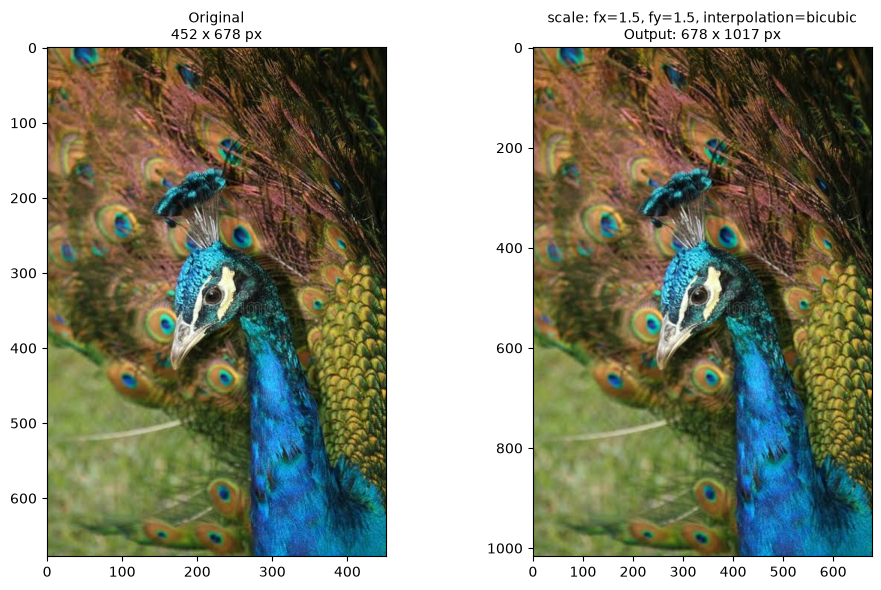

Saved output\result_scale_enlarge_proportional.png  |  output shape (height, width, channels) = (1017, 678, 3)


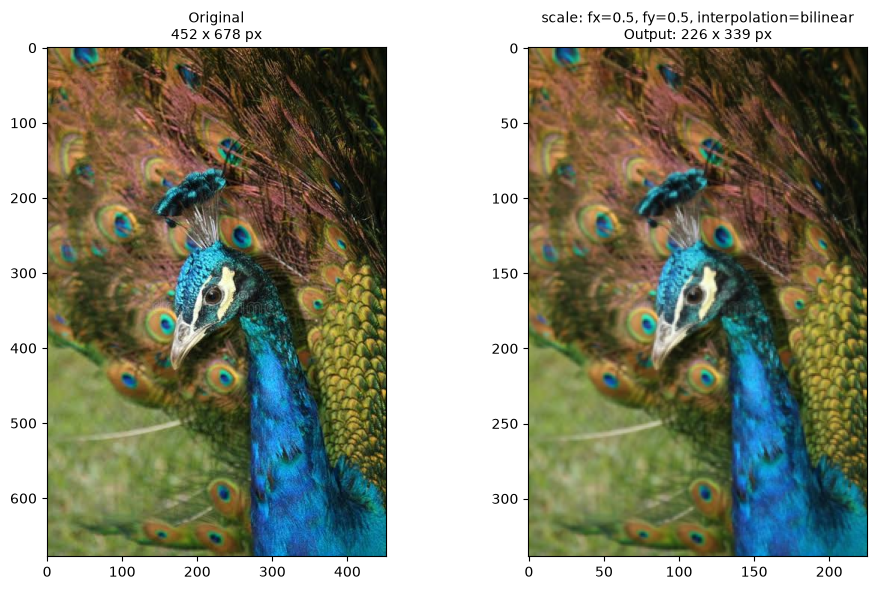

Saved output\result_scale_reduce_proportional.png  |  output shape (height, width, channels) = (339, 226, 3)


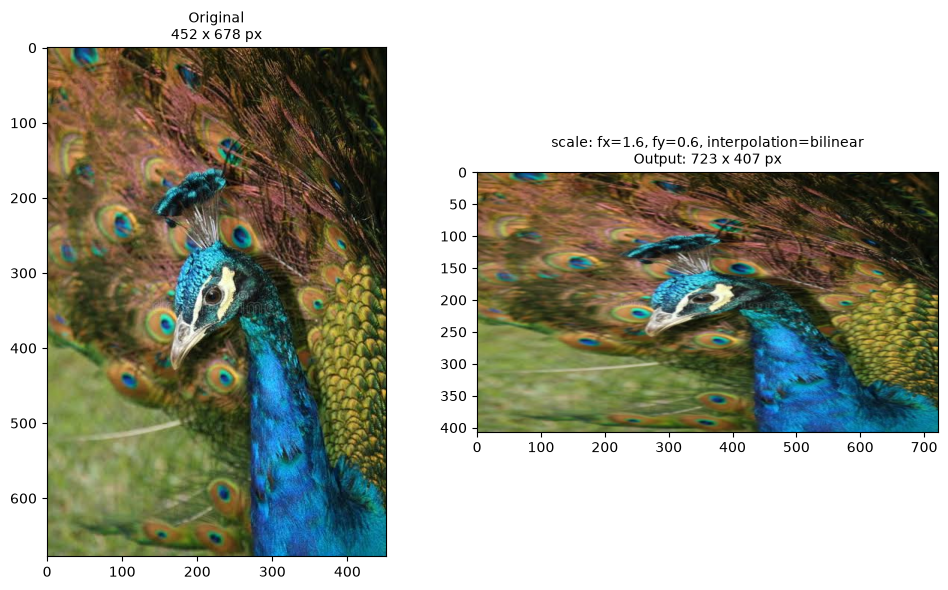

Saved output\result_scale_nonproportional.png  |  output shape (height, width, channels) = (407, 723, 3)

Aspect ratio (width / height):
  Original                               452 x 678   -> 0.667
  Enlarged x1.5 (proportional)           678 x 1017  -> 0.667
  Reduced x0.5 (proportional)            226 x 339   -> 0.667
  fx=1.6, fy=0.6 (non-proportional)      723 x 407   -> 1.776


In [7]:
enlarged = run_demo("scale", "scale_enlarge_proportional.png", fx=1.5, fy=1.5, interpolation="bicubic")
reduced  = run_demo("scale", "scale_reduce_proportional.png",  fx=0.5, fy=0.5, interpolation="bilinear")
stretched = run_demo("scale", "scale_nonproportional.png",     fx=1.6, fy=0.6, interpolation="bilinear")

print()
print("Aspect ratio (width / height):")
for label, img in [("Original", original), ("Enlarged x1.5 (proportional)", enlarged),
                   ("Reduced x0.5 (proportional)", reduced), ("fx=1.6, fy=0.6 (non-proportional)", stretched)]:
    h, w = img.shape[:2]
    print(f"  {label:36s} {w:5d} x {h:<5d} -> {w / h:.3f}")

#### 7.2 Cropping
Coordinates are in image (x, y) terms; `right` and `bottom` are **exclusive**, so the output is `right - left` pixels wide and `bottom - top` pixels tall.

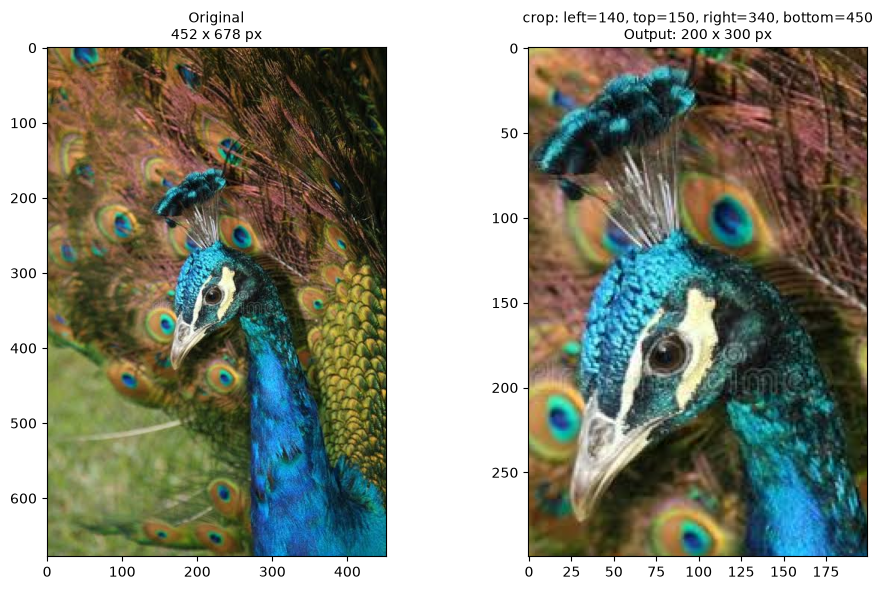

Saved output\result_crop_head.png  |  output shape (height, width, channels) = (300, 200, 3)
Expected size: 200 x 300; got 200 x 300


In [8]:
cropped = run_demo("crop", "crop_head.png", left=140, top=150, right=340, bottom=450)
print(f"Expected size: {340 - 140} x {450 - 150}; got {cropped.shape[1]} x {cropped.shape[0]}")

#### 7.3 Flipping – horizontal, vertical and both

Saved output\result_flip_horizontal.png
Saved output\result_flip_vertical.png
Saved output\result_flip_both.png


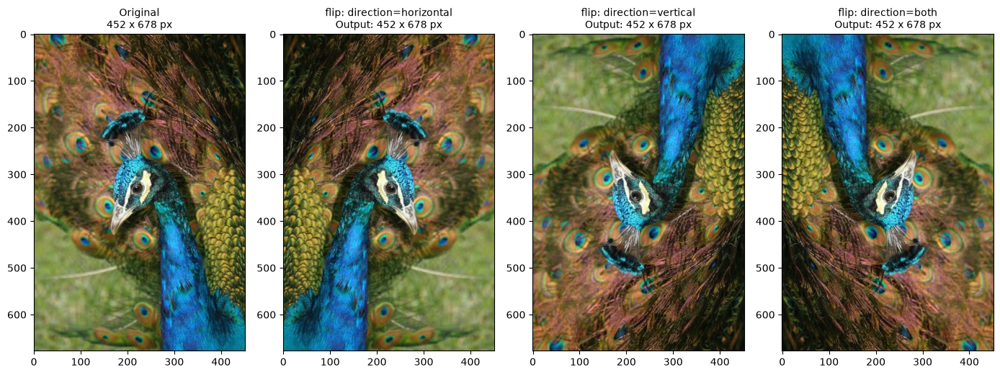

In [9]:
flip_results = {}
for direction in ("horizontal", "vertical", "both"):
    flip_results[direction] = transform(original, "flip", direction=direction)
    path = save_image(flip_results[direction], f"flip_{direction}.png")
    print(f"Saved {path}")

fig, axes = plt.subplots(1, 4, figsize=(14, 5))
show_image(axes[0], original)
axes[0].set_title(f"Original\n{orig_width} x {orig_height} px", fontsize=10)
for axis, direction in zip(axes[1:], flip_results):
    img = flip_results[direction]
    show_image(axis, img)
    axis.set_title(f"flip: direction={direction}\nOutput: {img.shape[1]} x {img.shape[0]} px", fontsize=10)
plt.tight_layout()
plt.show()

#### 7.4 Translation – shifts in opposite directions
The canvas keeps its original size. Pixels pushed past the edge are **clipped (lost)**, and the strip that is uncovered on the opposite side is filled with **black** (constant background value 0). Positive `tx` moves the picture right, positive `ty` moves it down.

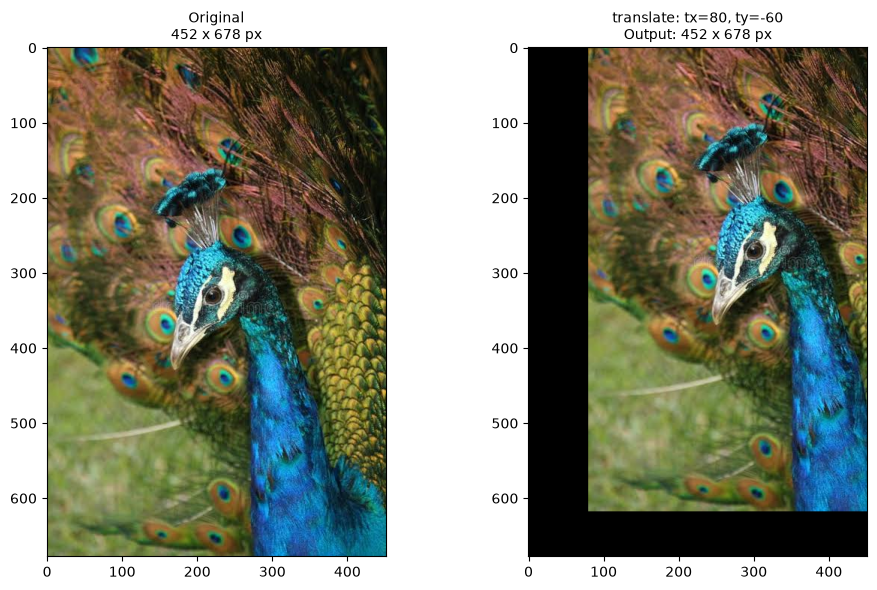

Saved output\result_translate_right_up.png  |  output shape (height, width, channels) = (678, 452, 3)


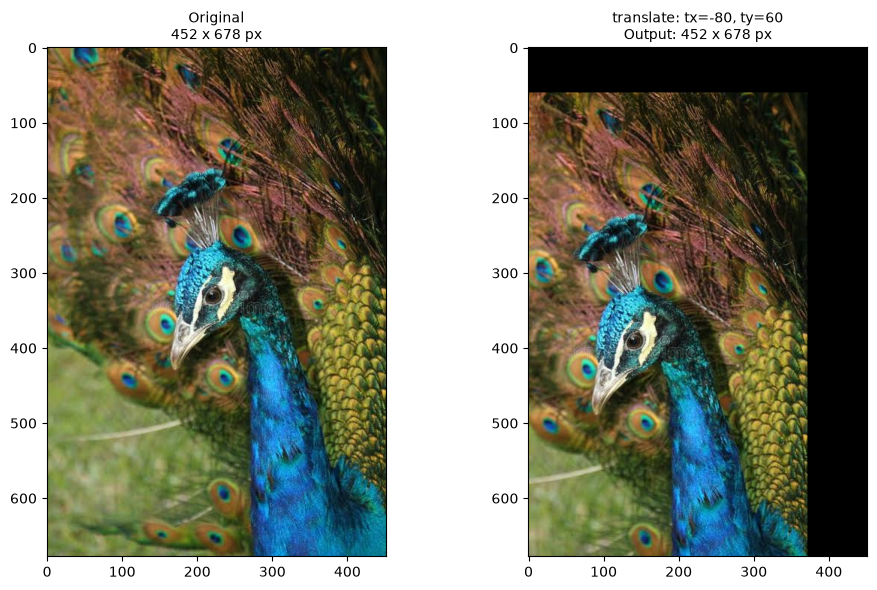

Saved output\result_translate_left_down.png  |  output shape (height, width, channels) = (678, 452, 3)


In [10]:
shift_a = run_demo("translate", "translate_right_up.png",   tx=80,  ty=-60)
shift_b = run_demo("translate", "translate_left_down.png", tx=-80, ty=60)

#### 7.5 Rotation – positive and negative angles
Rotation is about the image centre. A **positive angle turns the picture counter-clockwise** as seen on screen; a negative angle turns it clockwise (verified numerically in section 8). With `expand=False` the canvas keeps its size and the corners are cut off; with `expand=True` the canvas grows so that nothing is cut. Exposed areas are black.

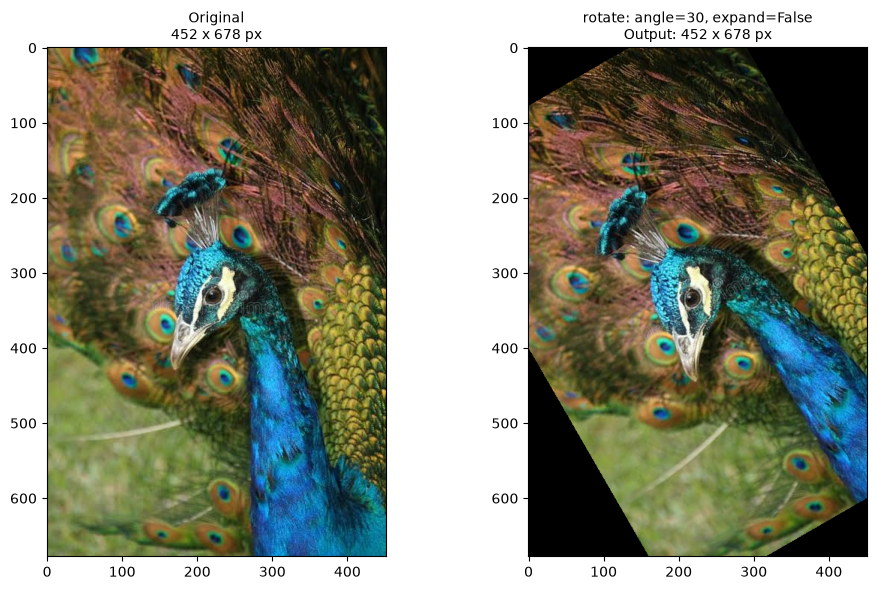

Saved output\result_rotate_plus30_noexpand.png  |  output shape (height, width, channels) = (678, 452, 3)


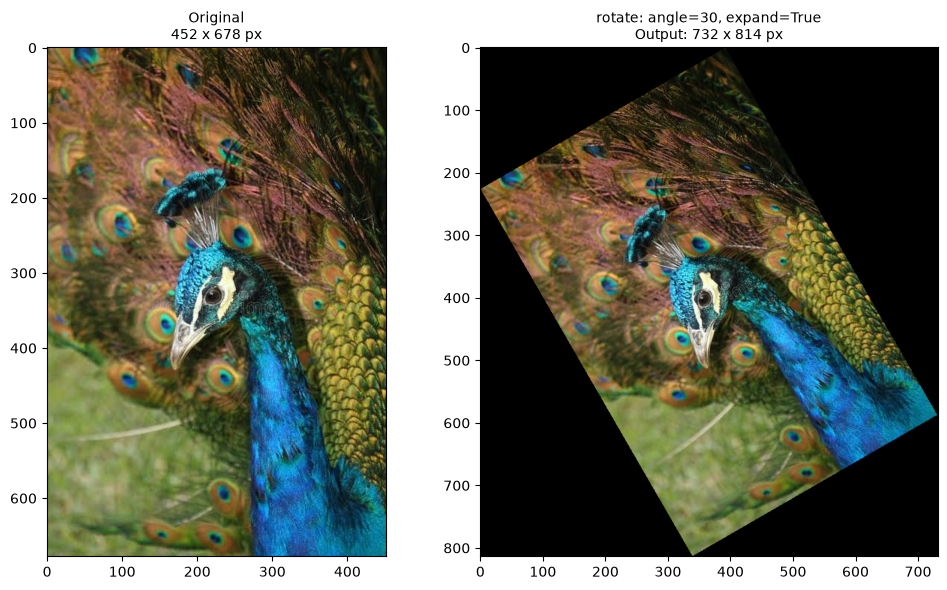

Saved output\result_rotate_plus30_expand.png  |  output shape (height, width, channels) = (814, 732, 3)


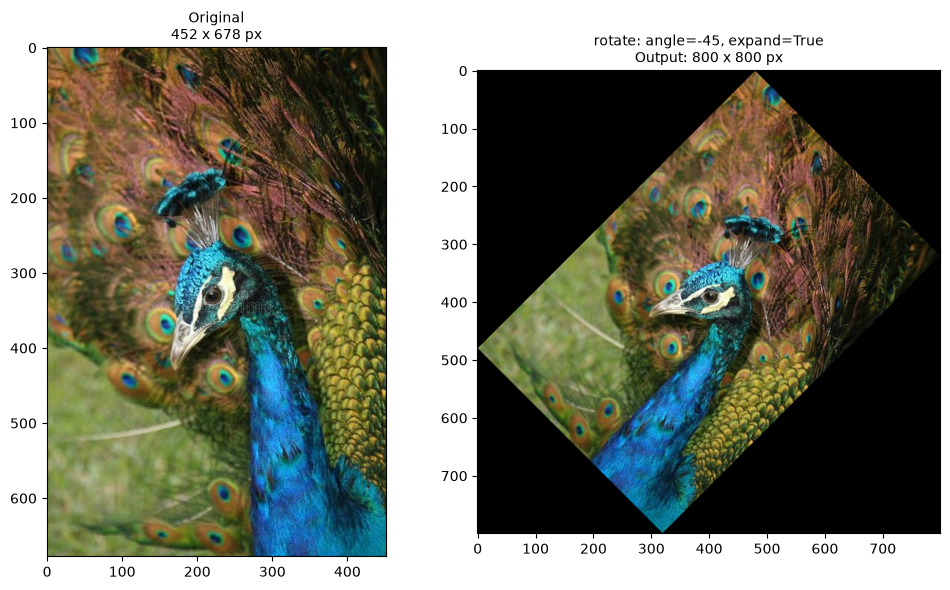

Saved output\result_rotate_minus45_expand.png  |  output shape (height, width, channels) = (800, 800, 3)


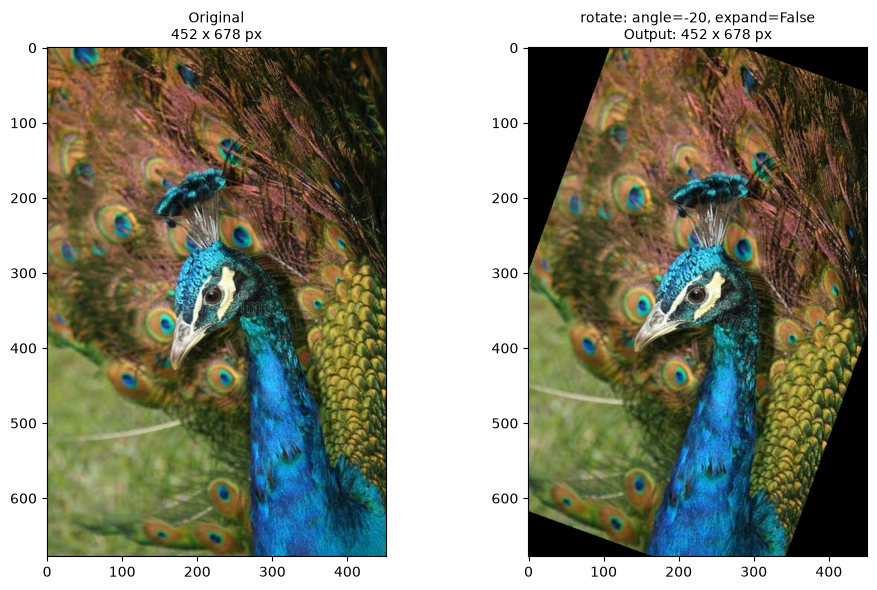

Saved output\result_rotate_minus20_noexpand.png  |  output shape (height, width, channels) = (678, 452, 3)


In [11]:
rot_a = run_demo("rotate", "rotate_plus30_noexpand.png",  angle=30,  expand=False)
rot_b = run_demo("rotate", "rotate_plus30_expand.png",    angle=30,  expand=True)
rot_c = run_demo("rotate", "rotate_minus45_expand.png",   angle=-45, expand=True)
rot_d = run_demo("rotate", "rotate_minus20_noexpand.png", angle=-20, expand=False)

### 8. Direction checks (numerical proof)
A small white square is placed at the middle-right of a black 101 × 101 image. If positive rotation is counter-clockwise, a 90° turn moves it to the **top**. If positive `tx` / `ty` mean right / down, the x position grows with `tx` and the y position grows with `ty`.

In [12]:
def marker_position(img):
    ys, xs = np.nonzero(img[..., 0] > 128)
    return round(float(xs.mean()), 1), round(float(ys.mean()), 1)      # (x, y)


marker = np.zeros((101, 101, 3), dtype=np.uint8)
marker[48:53, 90:95] = 255
print("Marker centre (x, y) at start        :", marker_position(marker))

turned = transform(marker, "rotate", angle=90, expand=False)
print("After rotate angle=+90               :", marker_position(turned), " -> top of the image => counter-clockwise")

turned_neg = transform(marker, "rotate", angle=-90, expand=False)
print("After rotate angle=-90               :", marker_position(turned_neg), " -> bottom of the image => clockwise")

moved = transform(marker, "translate", tx=-20, ty=15)
print("After translate tx=-20, ty=+15       :", marker_position(moved), " -> x decreased (left), y increased (down)")

Marker centre (x, y) at start        : (92.0, 50.0)
After rotate angle=+90               : (50.0, 8.0)  -> top of the image => counter-clockwise
After rotate angle=-90               : (50.0, 92.0)  -> bottom of the image => clockwise
After translate tx=-20, ty=+15       : (72.0, 65.0)  -> x decreased (left), y increased (down)


### 9. Interpolation comparison on one enlarged patch
A small patch around the eye (high-contrast edges) is cropped and enlarged 8× with each of the four interpolation methods, so the differences can be compared side by side.

Patch size: 56 x 48 px, enlarged 8x


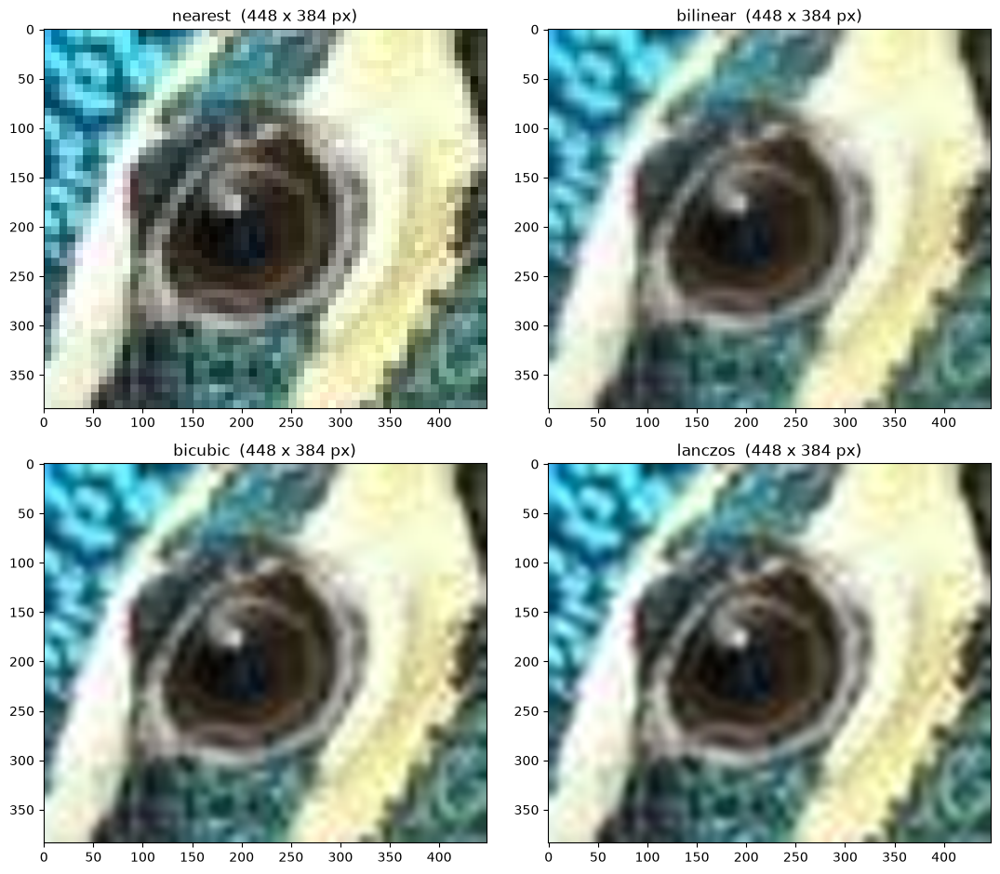

In [13]:
patch = transform(original, "crop", left=196, top=306, right=252, bottom=354)
print(f"Patch size: {patch.shape[1]} x {patch.shape[0]} px, enlarged 8x")

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for axis, method in zip(axes.ravel(), INTERPOLATIONS):
    big = transform(patch, "scale", fx=8, fy=8, interpolation=method)
    show_image(axis, big)
    axis.set_title(f"{method}  ({big.shape[1]} x {big.shape[0]} px)")
    save_image(big, f"interp_{method}.png")
plt.tight_layout()
plt.show()

**Observations (interpolation):** **Nearest-neighbour** copies the closest pixel, so edges show visible blocks and a staircase effect, and fine detail looks pixelated. **Bilinear** blends the neighbouring pixels linearly, giving smooth results but slightly soft edges. **Bicubic** and **Lanczos** use larger neighbourhoods and also look smooth; their edges around the eye and the white stripe look slightly crisper than bilinear, and the difference between these two is small on this patch (strong edges can show faint halos).

### 10. Rejected inputs
Every operation is given at least one invalid input. Each must be **rejected with a clear message** and no crash. (`transform` is called inside `try / except TransformError`.)

In [14]:
rejected_cases = [
    # (operation, parameters, what is wrong)
    ("scale",     dict(fx=-1.0, fy=1.0, interpolation="bilinear"),   "negative scale factor"),
    ("scale",     dict(fx=0, fy=1.0, interpolation="bilinear"),      "zero scale factor"),
    ("scale",     dict(fx=float("nan"), fy=1.0, interpolation="bilinear"), "NaN scale factor"),
    ("scale",     dict(fx=0.0001, fy=0.0001, interpolation="bilinear"),    "output would be empty (0 px)"),
    ("scale",     dict(fx=50, fy=50, interpolation="bilinear"),      "output exceeds maximum size"),
    ("scale",     dict(fx=2, fy=2, interpolation="bessel"),          "unsupported interpolation"),
    ("crop",      dict(left=300, top=0, right=100, bottom=100),      "left >= right"),
    ("crop",      dict(left=0, top=0, right=orig_width + 1, bottom=100), "right beyond image width"),
    ("crop",      dict(left=-5, top=0, right=100, bottom=100),       "negative left"),
    ("crop",      dict(left=10.5, top=0, right=100, bottom=100),     "non-integer coordinate"),
    ("flip",      dict(direction="diagonal"),                         "unsupported direction"),
    ("translate", dict(tx="abc", ty=0),                               "non-numeric offset"),
    ("translate", dict(tx=float("inf"), ty=0),                        "infinite offset"),
    ("rotate",    dict(angle="abc", expand=True),                     "non-numeric angle"),
    ("rotate",    dict(angle=float("nan"), expand=True),              "NaN angle"),
    ("rotate",    dict(angle=float("inf"), expand=False),             "infinite angle"),
    ("rotate",    dict(angle=30, expand="maybe"),                     "invalid expand choice"),
    ("spin",      dict(angle=30),                                     "unknown operation"),
    ("rotate",    dict(angle=30),                                     "missing required parameter"),
    ("flip",      dict(direction="both", extra=1),                    "unexpected parameter"),
]

for operation, params, reason in rejected_cases:
    try:
        transform(original, operation, **params)
        print(f"[NOT REJECTED - BUG] {operation} {params}")
    except TransformError as error:
        print(f"[{operation}] {describe_params(params)}   ({reason})")
        print(f"      -> Rejected: {error}")

print()
print("Text typed by a user is checked before transform is called:")
text_cases = [
    (parse_float, ("angle", "abc")),
    (parse_float, ("angle", "nan")),
    (parse_float, ("tx", "inf")),
    (parse_int, ("left", "10.5")),
    (parse_bool, ("expand", "maybe")),
    (make_choice_parser(FLIP_DIRECTIONS), ("direction", "diagonal")),
]
for parser, (name, text) in text_cases:
    try:
        parser(name, text)
        print(f"[NOT REJECTED - BUG] {name}={text!r}")
    except TransformError as error:
        print(f"  {name}={text!r} -> Rejected: {error}")

[scale] fx=-1.0, fy=1.0, interpolation=bilinear   (negative scale factor)
      -> Rejected: Scale factors must be greater than zero, got fx=-1.0, fy=1.0.
[scale] fx=0, fy=1.0, interpolation=bilinear   (zero scale factor)
      -> Rejected: Scale factors must be greater than zero, got fx=0.0, fy=1.0.
[scale] fx=nan, fy=1.0, interpolation=bilinear   (NaN scale factor)
      -> Rejected: 'fx' must be finite (not NaN or infinity), got nan.
[scale] fx=0.0001, fy=0.0001, interpolation=bilinear   (output would be empty (0 px))
      -> Rejected: Scaling would produce an empty image (0 x 0 px).
[scale] fx=50, fy=50, interpolation=bilinear   (output exceeds maximum size)
      -> Rejected: Scale factor 'fx'=50.0 makes the output larger than the maximum side of 4000 px.
[scale] fx=2, fy=2, interpolation=bessel   (unsupported interpolation)
      -> Rejected: Unsupported interpolation 'bessel'. Choose from: nearest, bilinear, bicubic, lanczos.
[crop] left=300, top=0, right=100, bottom=100   (lef

### 11. Valid boundary inputs must be accepted
Zero values and negative offsets / angles are **valid** and must not be rejected.

In [15]:
boundary_cases = [
    ("translate", dict(tx=0, ty=0)),
    ("translate", dict(tx=-30, ty=0)),
    ("translate", dict(tx=0, ty=-25.5)),
    ("rotate",    dict(angle=0, expand=False)),
    ("rotate",    dict(angle=-90, expand=True)),
    ("rotate",    dict(angle=720, expand=False)),
    ("crop",      dict(left=0, top=0, right=orig_width, bottom=orig_height)),
    ("crop",      dict(left=orig_width - 1, top=orig_height - 1, right=orig_width, bottom=orig_height)),
    ("scale",     dict(fx=1, fy=1, interpolation="lanczos")),
]
rows = []
for operation, params in boundary_cases:
    result = transform(original, operation, **params)
    rows.append((operation, describe_params(params), "Accepted", f"{result.shape[1]} x {result.shape[0]}"))
print_table(["Operation", "Parameters", "Result", "Output size"], rows)

+-----------+------------------------------------------+----------+-------------+
| Operation | Parameters                               | Result   | Output size |
+-----------+------------------------------------------+----------+-------------+
| translate | tx=0, ty=0                               | Accepted | 452 x 678   |
| translate | tx=-30, ty=0                             | Accepted | 452 x 678   |
| translate | tx=0, ty=-25.5                           | Accepted | 452 x 678   |
| rotate    | angle=0, expand=False                    | Accepted | 452 x 678   |
| rotate    | angle=-90, expand=True                   | Accepted | 678 x 452   |
| rotate    | angle=720, expand=False                  | Accepted | 452 x 678   |
| crop      | left=0, top=0, right=452, bottom=678     | Accepted | 452 x 678   |
| crop      | left=451, top=677, right=452, bottom=678 | Accepted | 1 x 1       |
| scale     | fx=1, fy=1, interpolation=lanczos        | Accepted | 452 x 678   |
+-----------+---

### 12. Identity checks
Operations that should change nothing are compared to the original pixel by pixel.

In [16]:
identity_cases = [
    ("Scale fx=1, fy=1 (nearest)",  "scale", dict(fx=1, fy=1, interpolation="nearest")),
    ("Scale fx=1, fy=1 (bilinear)", "scale", dict(fx=1, fy=1, interpolation="bilinear")),
    ("Scale fx=1, fy=1 (bicubic)",  "scale", dict(fx=1, fy=1, interpolation="bicubic")),
    ("Scale fx=1, fy=1 (lanczos)",  "scale", dict(fx=1, fy=1, interpolation="lanczos")),
    ("Translate tx=0, ty=0",        "translate", dict(tx=0, ty=0)),
    ("Rotate 0 deg, expand=False",  "rotate", dict(angle=0, expand=False)),
    ("Rotate 0 deg, expand=True",   "rotate", dict(angle=0, expand=True)),
    ("Rotate 360 deg, expand=False", "rotate", dict(angle=360, expand=False)),
    ("Crop the whole image",        "crop", dict(left=0, top=0, right=orig_width, bottom=orig_height)),
]
expected = "Same shape, identical pixels"
rows = []
for label, operation, params in identity_cases:
    result = transform(original, operation, **params)
    same_shape = result.shape == original.shape
    max_diff = int(np.abs(result.astype(int) - original.astype(int)).max()) if same_shape else "n/a"
    passed = same_shape and np.array_equal(result, original)
    actual = f"shape {result.shape}, max pixel diff = {max_diff}"
    rows.append((label, expected, actual, "Pass" if passed else "Fail"))
print_table(["Case", "Expected behaviour", "Actual behaviour", "Result"], rows)

+------------------------------+------------------------------+-----------------------------------------+--------+
| Case                         | Expected behaviour           | Actual behaviour                        | Result |
+------------------------------+------------------------------+-----------------------------------------+--------+
| Scale fx=1, fy=1 (nearest)   | Same shape, identical pixels | shape (678, 452, 3), max pixel diff = 0 | Pass   |
| Scale fx=1, fy=1 (bilinear)  | Same shape, identical pixels | shape (678, 452, 3), max pixel diff = 0 | Pass   |
| Scale fx=1, fy=1 (bicubic)   | Same shape, identical pixels | shape (678, 452, 3), max pixel diff = 0 | Pass   |
| Scale fx=1, fy=1 (lanczos)   | Same shape, identical pixels | shape (678, 452, 3), max pixel diff = 0 | Pass   |
| Translate tx=0, ty=0         | Same shape, identical pixels | shape (678, 452, 3), max pixel diff = 0 | Pass   |
| Rotate 0 deg, expand=False   | Same shape, identical pixels | shape (678, 452,

### 13. Was the original left unchanged?

In [17]:
print("Original is still identical to the backup copy:", np.array_equal(original, original_backup))
print("Original array is read-only:", not original.flags.writeable)
print("Saved files:")
for file in saved_files:
    print("  ", file)

Original is still identical to the backup copy: True
Original array is read-only: True
Saved files:
   output\result_scale_enlarge_proportional.png
   output\result_scale_reduce_proportional.png
   output\result_scale_nonproportional.png
   output\result_crop_head.png
   output\result_flip_horizontal.png
   output\result_flip_vertical.png
   output\result_flip_both.png
   output\result_translate_right_up.png
   output\result_translate_left_down.png
   output\result_rotate_plus30_noexpand.png
   output\result_rotate_plus30_expand.png
   output\result_rotate_minus45_expand.png
   output\result_rotate_minus20_noexpand.png
   output\result_interp_nearest.png
   output\result_interp_bilinear.png
   output\result_interp_bicubic.png
   output\result_interp_lanczos.png


### 14. Short explanations

**Image coordinates vs array indexing.** In image coordinates a point is written **(x, y)**: the origin is the top-left corner, *x* grows to the right (columns) and *y* grows **downwards** (rows). OpenCV functions such as `cv.resize` and `cv.warpAffine` take sizes as **(width, height)**. NumPy arrays are indexed **[row, column] = [y, x]** and `image.shape` is **(height, width, channels)**. That is why cropping is `image[top:bottom, left:right]` and why `height, width = image.shape[:2]` must be unpacked in that order.

**Aspect-ratio distortion.** The aspect ratio (width ÷ height) is preserved only when `fx = fy` (apart from rounding to whole pixels). With `fx = 1.6, fy = 0.6` the output is stretched horizontally and squashed vertically, so shapes look distorted.

**Rotation canvas expansion.** With `expand=False` the output keeps the original size, so the corners of the rotated picture fall outside the canvas and are cut off. With `expand=True` the canvas is enlarged to the bounding box of the rotated rectangle, `width·|cos θ| + height·|sin θ|` by `width·|sin θ| + height·|cos θ|`, so nothing is lost; the new empty corners are filled with black.

**Translation clipping.** The canvas does not grow when the picture is shifted. The part pushed beyond the edge is **lost** (clipped, not wrapped around), and the strip on the opposite side that is no longer covered is filled with **black**. Shifting back by the opposite amount therefore does not restore the lost pixels.

### 15. Interactive transformation (user prompts)
Run this cell **last**. It asks you to choose an operation and enter its parameters; the values are passed straight to `transform`. Invalid text or a rejected region produces an error message and you are asked again — nothing crashes. Type `q` at the operation prompt to stop.

In [18]:
def run_interactive(source):
    src_h, src_w = source.shape[:2]
    print(f"Image size: {src_w} x {src_h} px")
    counter = 0
    while True:
        choice = input(f"Operation ({'/'.join(OPERATIONS)}), or q to quit: ").strip().lower()
        if choice == "q":
            print("Interactive session finished.")
            return
        if choice not in OPERATIONS:
            print(f"Error: unknown operation {choice!r}. Choose from: {', '.join(OPERATIONS)} (or q).")
            continue

        params = {}
        for name, prompt, parser in PARAMETER_PROMPTS[choice]:
            while True:
                try:
                    params[name] = parser(name, input(f"  {prompt}: "))
                    break
                except TransformError as error:
                    print(f"  Error: {error}  Please try again.")

        try:
            result = transform(source, choice, **params)
        except TransformError as error:
            print(f"Rejected by transform: {error}")
            print("Please enter the values for this operation again.")
            continue

        counter += 1
        show_comparison(source, result, choice, params)
        print(f"Saved {save_image(result, f'interactive_{counter}_{choice}.png')}\n")


run_interactive(original)

Image size: 452 x 678 px
Interactive session finished.
